## Balanced Random Forest

1. Balanced Random Forest is a bagging and __undersampling__ Technique.

2. It does not remove the majority class from the dataset instead it only gives few portion of majority class to each tree during its training.

3. Balanced Random Forest changes the sampling process for individual trees.

Imagine the original dataset contains 950 majority examples and 50 minority examples. In a simplified example, each tree might train on:
- 50 majority examples sampled from the majority class.
- 50 minority examples sampled from the minority class.
This gives the tree a balanced training sample of 100 observations.

The next tree can use a different sample of majority examples. Across many trees, the forest can learn from different portions of the majority class while giving minority examples more representation.

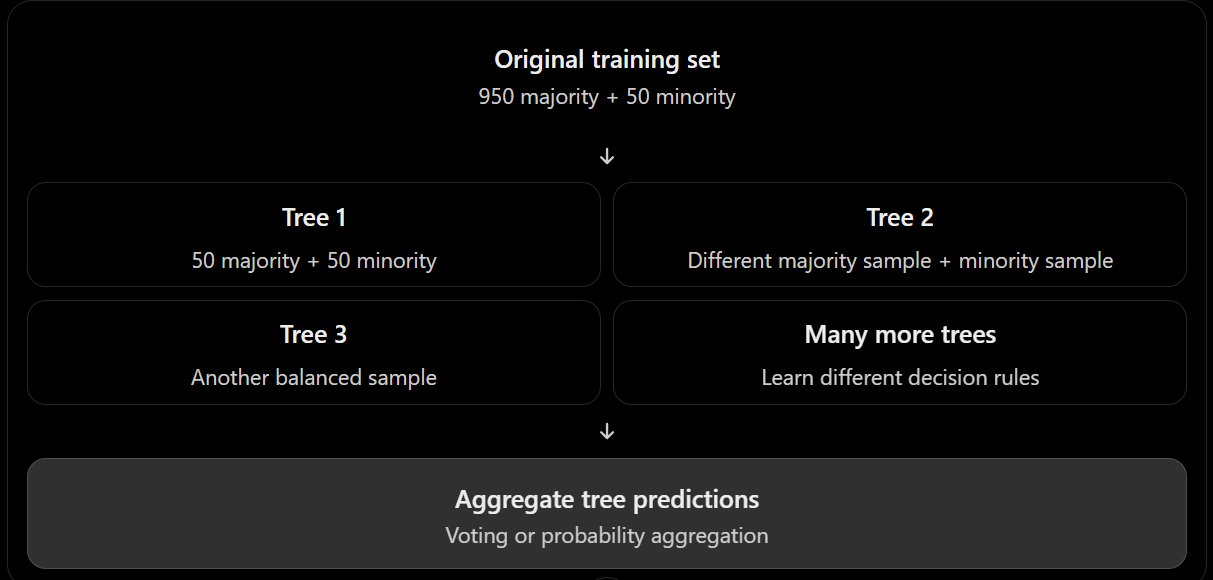

__Advantages__

- Gives each tree a stronger opportunity to learn minority patterns.
- Can reduce majority-class dominance.
- Retains the diversity of a forest.

__Limitations__

- Each tree sees fewer majority examples, potentially losing useful information.
- Results depend on the sampling strategy and the number of trees.
- A balanced training sample does not represent the real-world class prior, so predicted probabilities may require calibration.

## Easy Ensemble

1. Easy Ensemble follows the same idea as Balanced Random Forest, with a few differences in the details.

2. It is also a bagging undersampling Algorithm.

3. How it works (950 majority, 50 minority)

Subset 1: take all 50 minority samples plus 50 randomly chosen majority samples. Train an AdaBoost model on it.
Subset 2: take the same 50 minority samples plus a different random 50 majority samples. Train another AdaBoost model.
Repeat this for N subsets (10 by default in imblearn).
For prediction, combine all the models’ outputs by averaging or voting.

So you get many balanced mini-datasets, one strong model per dataset, and a final combined answer.

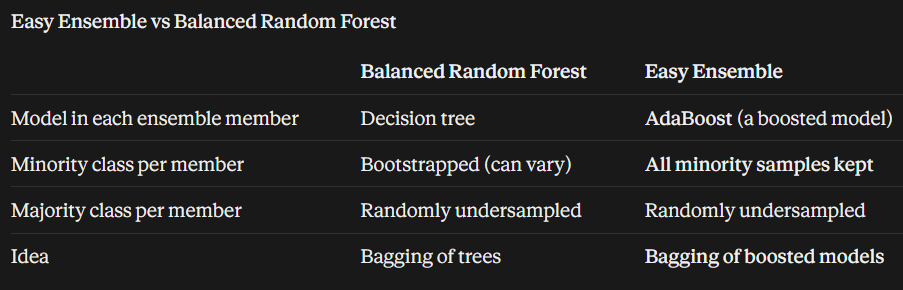

## RUSBoost

RUSBoost integrates random undersampling with boosting.

At a high level:
1. Randomly undersample the majority class.
2. Train a weak learner on the reduced dataset.
3. Update observation weights according to the boosting algorithm.
4. Repeat the process across boosting rounds. (Train Multiple Weak Learners)
5. Combine the weak learners into a final prediction.
The undersampling reduces the dominance of the majority class, while boosting builds a stronger model over successive rounds.

__Undersampling is integrated in Boosting Rounds. We do not create a balanced dataset upfront and train all the weak learners.__

One caveat: undersampling can discard informative majority examples, and boosting can focus too heavily on noisy or mislabeled minority examples.

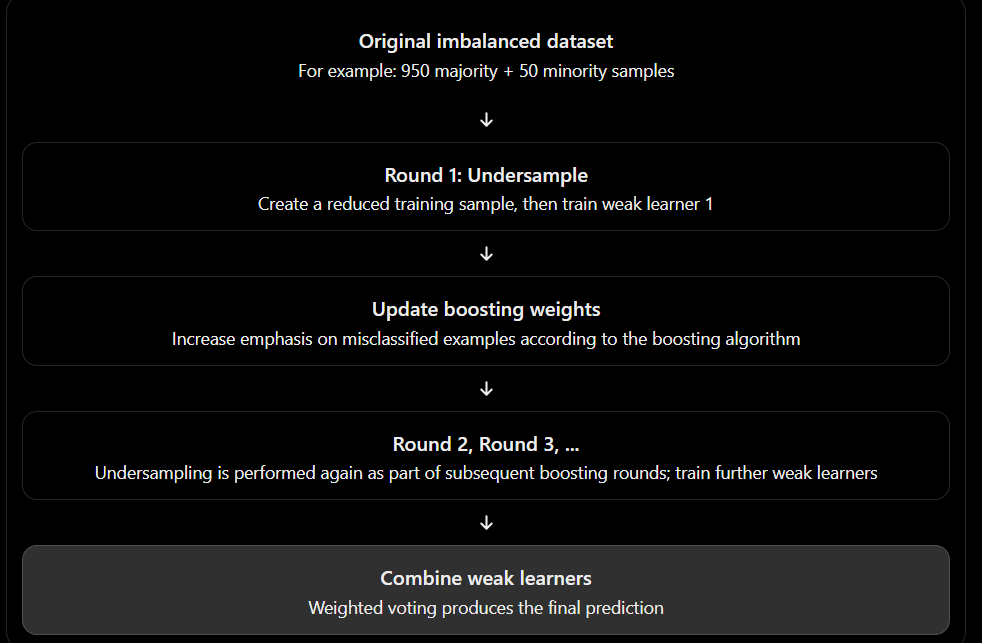


## Tabular Comparison Between the Techniques

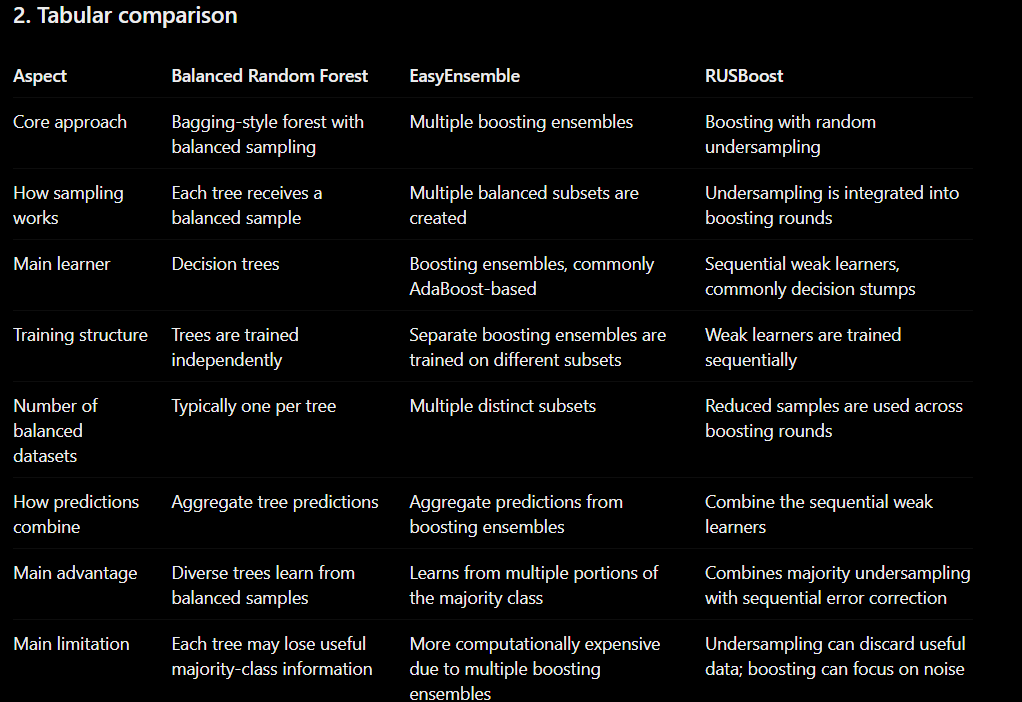

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score
)

In [3]:
sns.set_theme(style="whitegrid")

In [4]:
# Generate an imbalanced binary classification dataset
X, y = make_classification(
    n_samples=2000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.95, 0.05],
    class_sep=0.8,
    flip_y=0.01,
    random_state=42
)

df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])
df["Target"] = y

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Target"].value_counts().sort_index())
print("\nClass percentages:")
print((df["Target"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (2000, 3)

Class distribution:
Target
0    1893
1     107
Name: count, dtype: int64

Class percentages:
Target
0    94.65
1     5.35
Name: proportion, dtype: float64


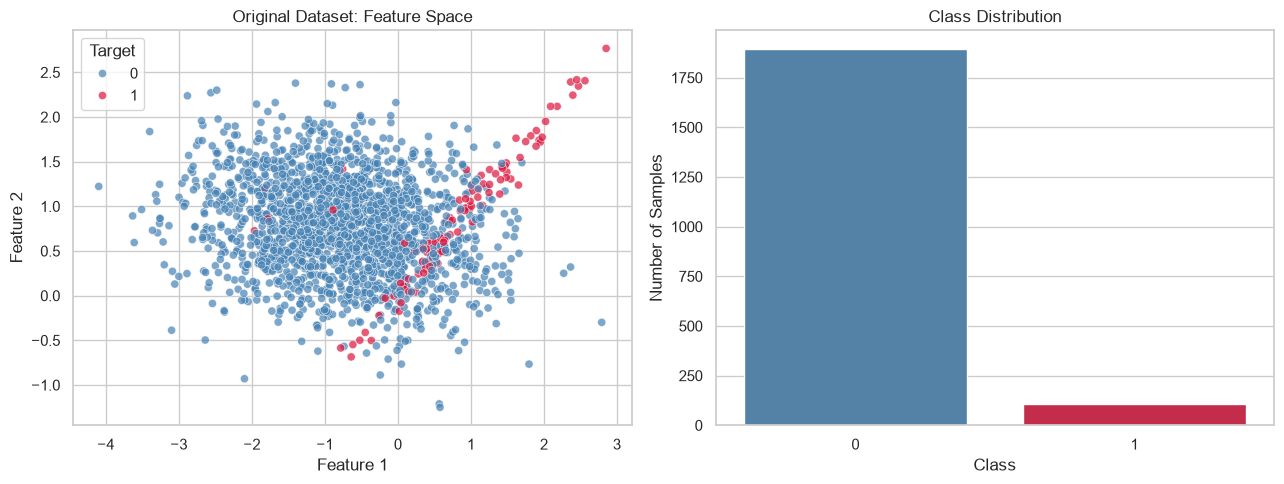

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter plot
sns.scatterplot(
    data=df,
    x="Feature 1",
    y="Feature 2",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.7,
    s=35,
    ax=axes[0]
)
axes[0].set_title("Original Dataset: Feature Space")

# Class counts
sns.countplot(
    data=df,
    x="Target",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Class Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training distribution:
0    1420
1      80
Name: count, dtype: int64

Test distribution:
0    473
1     27
Name: count, dtype: int64


## Baseline Model

BASELINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

Majority (0)      0.949     0.989     0.969       473
Minority (1)      0.286     0.074     0.118        27

    accuracy                          0.940       500
   macro avg      0.618     0.532     0.543       500
weighted avg      0.913     0.940     0.923       500

Baseline Average Precision: 0.241


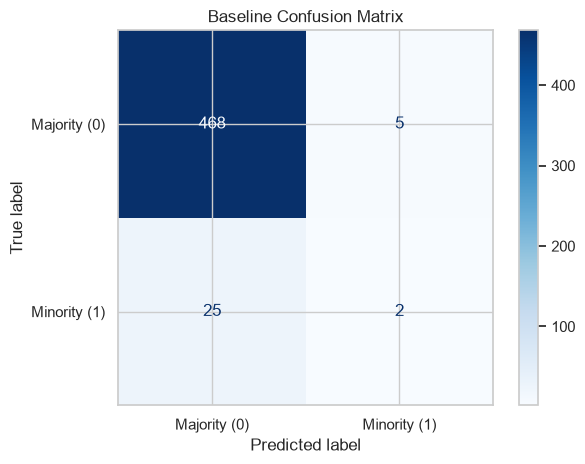

In [7]:
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_scaled, y_train)

baseline_pred = baseline_model.predict(X_test_scaled)
baseline_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

print("BASELINE CLASSIFICATION REPORT")
print(classification_report(
    y_test, baseline_pred,
    target_names=["Majority (0)", "Minority (1)"],
    digits=3,
    zero_division=0
))

print("Baseline Average Precision:",
      round(average_precision_score(y_test, baseline_proba), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_pred,
    display_labels=["Majority (0)", "Minority (1)"],
    cmap="Blues"
)
plt.title("Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

In [8]:
print("Training shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training shape: (1500, 2)
Test shape: (500, 2)

Training class distribution:
0    1420
1      80
Name: count, dtype: int64

Test class distribution:
0    473
1     27
Name: count, dtype: int64


## Balanced Random Forest

BALANCED RANDOM FOREST
              precision    recall  f1-score   support

Majority (0)      0.986     0.877     0.928       473
Minority (1)      0.266     0.778     0.396        27

    accuracy                          0.872       500
   macro avg      0.626     0.828     0.662       500
weighted avg      0.947     0.872     0.900       500

Average Precision: 0.327


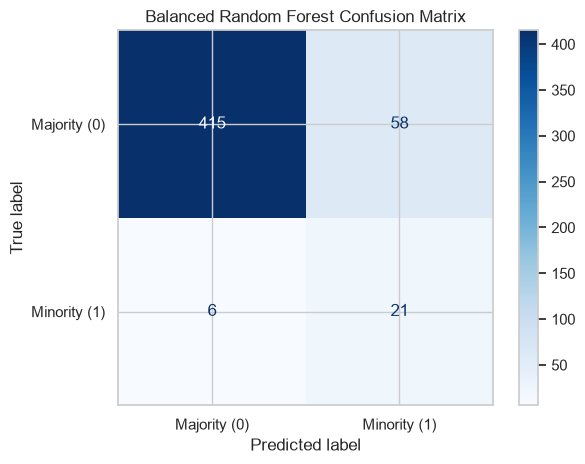

In [9]:
from imblearn.ensemble import BalancedRandomForestClassifier

brf_model = BalancedRandomForestClassifier(
    n_estimators=100,
    sampling_strategy="all",
    replacement=True,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

brf_model.fit(X_train_scaled, y_train)

brf_pred = brf_model.predict(X_test_scaled)
brf_proba = brf_model.predict_proba(X_test_scaled)[:, 1]

print("BALANCED RANDOM FOREST")
print(classification_report(
    y_test,
    brf_pred,
    target_names=["Majority (0)", "Minority (1)"],
    digits=3,
    zero_division=0
))

print("Average Precision:",
      round(average_precision_score(y_test, brf_proba), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    brf_pred,
    display_labels=["Majority (0)", "Minority (1)"],
    cmap="Blues"
)
plt.title("Balanced Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

Here, sampling_strategy="all" requests resampling of all classes to the minority-class count for each tree, and replacement=True allows sampling with replacement. bootstrap=False is appropriate for this balanced-sampling configuration in current imbalanced-learn versions.

## Easy Ensemble

EASYENSEMBLE
              precision    recall  f1-score   support

Majority (0)      0.981     0.757     0.854       473
Minority (1)      0.148     0.741     0.247        27

    accuracy                          0.756       500
   macro avg      0.564     0.749     0.551       500
weighted avg      0.936     0.756     0.822       500

Average Precision: 0.172


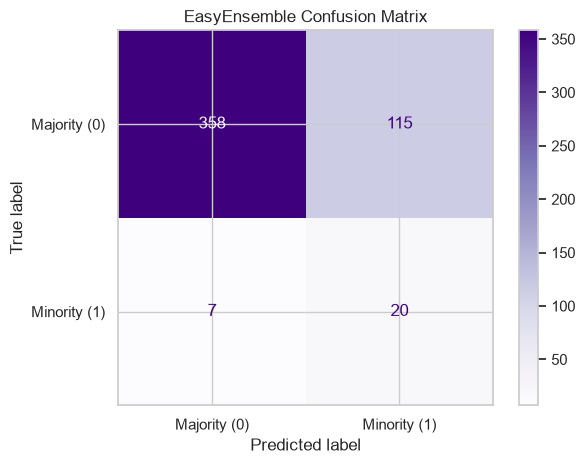

In [10]:
from imblearn.ensemble import EasyEnsembleClassifier

easy_model = EasyEnsembleClassifier(
    n_estimators=10,
    sampling_strategy="auto",
    replacement=False,
    random_state=42,
    n_jobs=-1
)

easy_model.fit(X_train_scaled, y_train)

easy_pred = easy_model.predict(X_test_scaled)
easy_proba = easy_model.predict_proba(X_test_scaled)[:, 1]

print("EASYENSEMBLE")
print(classification_report(
    y_test,
    easy_pred,
    target_names=["Majority (0)", "Minority (1)"],
    digits=3,
    zero_division=0
))

print("Average Precision:",
      round(average_precision_score(y_test, easy_proba), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    easy_pred,
    display_labels=["Majority (0)", "Minority (1)"],
    cmap="Purples"
)
plt.title("EasyEnsemble Confusion Matrix")
plt.tight_layout()
plt.show()

RUSBOOST
              precision    recall  f1-score   support

Majority (0)      0.978     0.757     0.853       473
Minority (1)      0.142     0.704     0.236        27

    accuracy                          0.754       500
   macro avg      0.560     0.730     0.545       500
weighted avg      0.933     0.754     0.820       500

Average Precision: 0.136


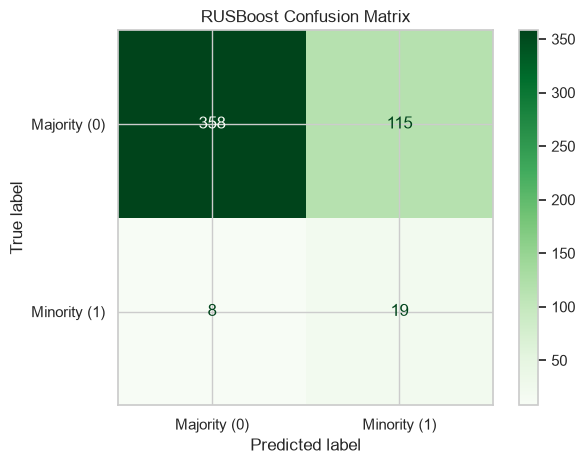

In [11]:
from imblearn.ensemble import RUSBoostClassifier

rusboost_model = RUSBoostClassifier(
    n_estimators=100,
    learning_rate=0.1,
    sampling_strategy="auto",
    random_state=42
)

rusboost_model.fit(X_train_scaled, y_train)

rus_pred = rusboost_model.predict(X_test_scaled)
rus_proba = rusboost_model.predict_proba(X_test_scaled)[:, 1]

print("RUSBOOST")
print(classification_report(
    y_test,
    rus_pred,
    target_names=["Majority (0)", "Minority (1)"],
    digits=3,
    zero_division=0
))

print("Average Precision:",
      round(average_precision_score(y_test, rus_proba), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rus_pred,
    display_labels=["Majority (0)", "Minority (1)"],
    cmap="Greens"
)
plt.title("RUSBoost Confusion Matrix")
plt.tight_layout()
plt.show()

In [17]:
def evaluate_model(y_true, y_pred, y_proba, name):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Minority Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Minority Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Minority F1": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_true, y_proba
        )
    }

ensemble_results = pd.DataFrame([
    evaluate_model(y_test, brf_pred, brf_proba, "Balanced RF"),
    evaluate_model(y_test, easy_pred, easy_proba, "EasyEnsemble"),
    evaluate_model(y_test, rus_pred, rus_proba, "RUSBoost")
]).set_index("Model")

print(ensemble_results.round(3))

              Accuracy  Minority Precision  Minority Recall  Minority F1  \
Model                                                                      
Balanced RF      0.872               0.266            0.778        0.396   
EasyEnsemble     0.756               0.148            0.741        0.247   
RUSBoost         0.754               0.142            0.704        0.236   

              Average Precision  
Model                            
Balanced RF               0.327  
EasyEnsemble              0.172  
RUSBoost                  0.136  


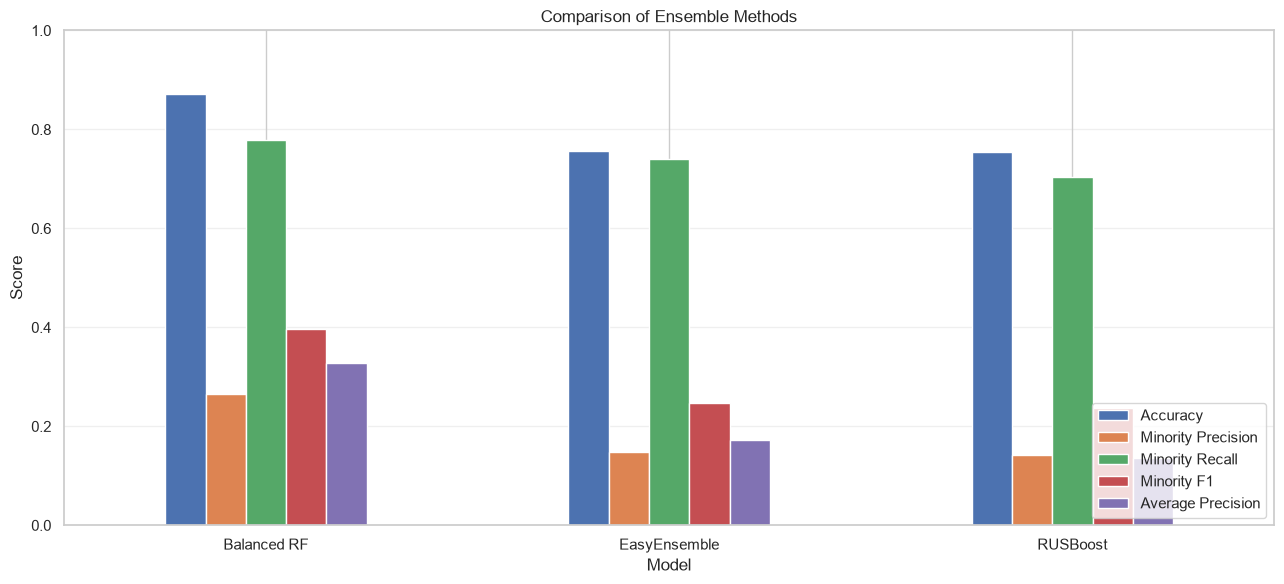

In [13]:
ensemble_results.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparison of Ensemble Methods")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Comparing Decision Boundaries from each Techniques

In [15]:
def plot_decision_boundary(model, ax, title):
    x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
    y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    probabilities = model.predict_proba(grid)[:, 1].reshape(xx.shape)

    ax.contourf(
        xx, yy, probabilities,
        levels=[0, 0.5, 1],
        colors=["#DCEAF7", "#F8DDE2"],
        alpha=0.8
    )
    ax.contour(
        xx, yy, probabilities,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    ax.scatter(
        X_test_scaled[:, 0],
        X_test_scaled[:, 1],
        c=y_test,
        cmap="coolwarm",
        edgecolors="white",
        s=25,
        alpha=0.8
    )

    ax.set_title(title)
    ax.set_xlabel("Feature 1 (scaled)")
    ax.set_ylabel("Feature 2 (scaled)")

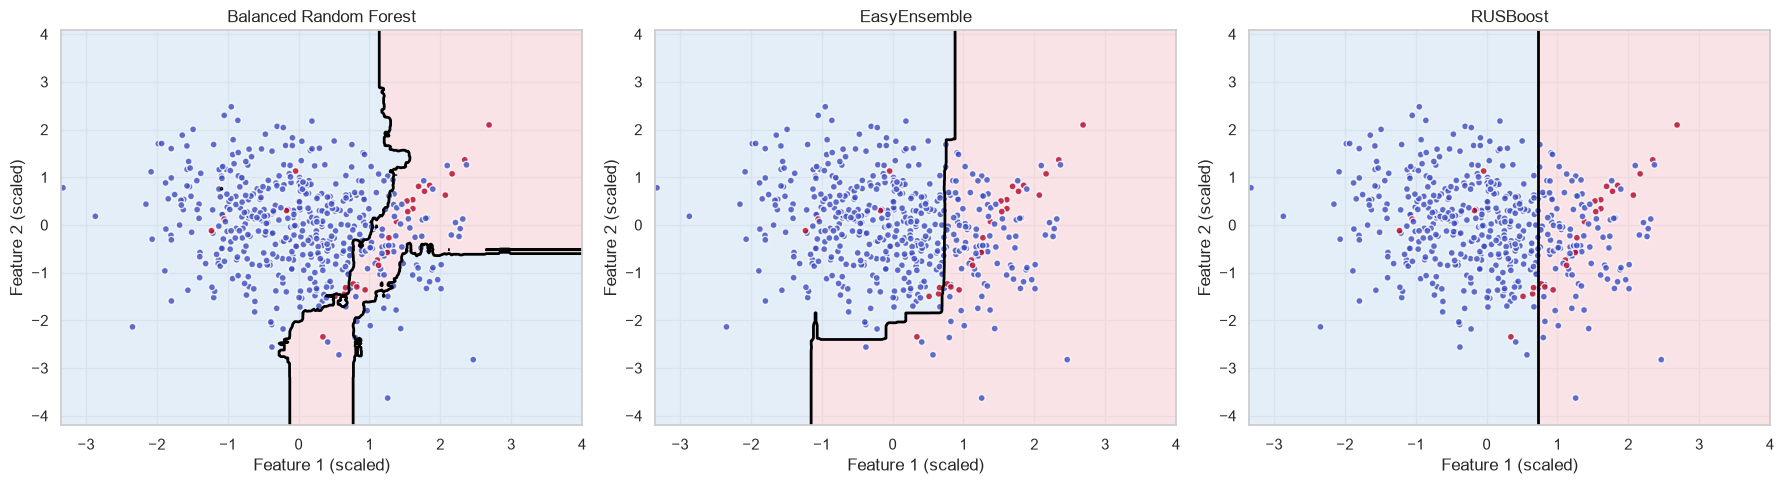

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_decision_boundary(
    brf_model, axes[0], "Balanced Random Forest"
)

plot_decision_boundary(
    easy_model, axes[1], "EasyEnsemble"
)

plot_decision_boundary(
    rusboost_model, axes[2], "RUSBoost"
)

plt.tight_layout()
plt.show()

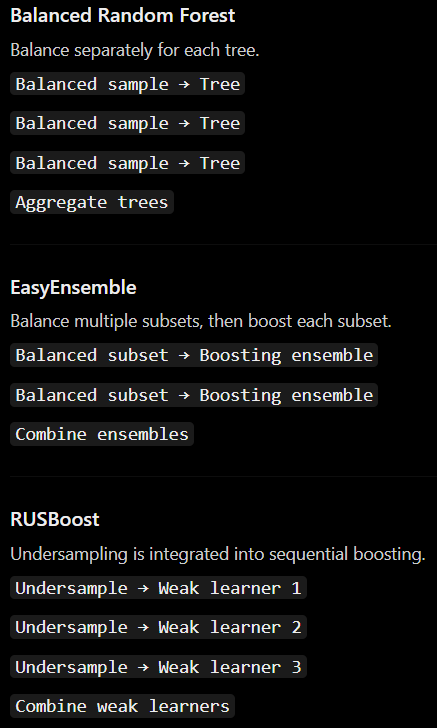

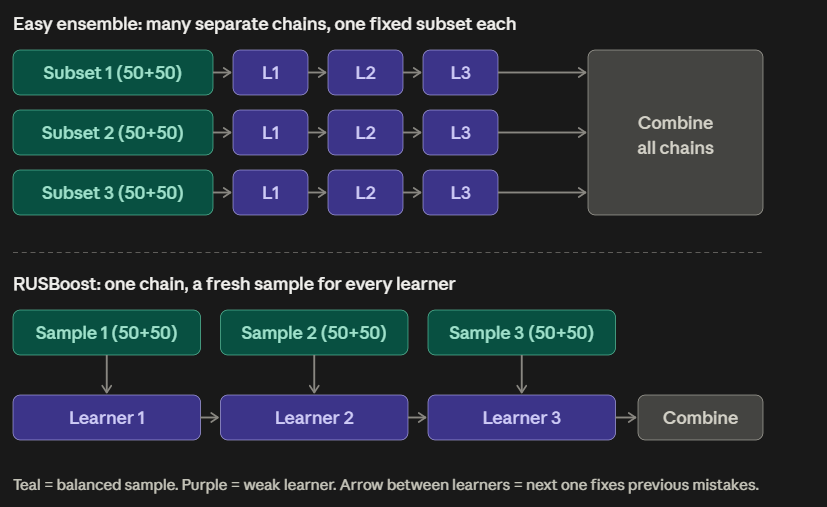